# 20. Robustez y estabilidad de las métricas

Un solo número («AUC = 0,81») esconde tres fuentes de variabilidad que la sección 5.4 del enunciado pide hacer
visibles:

1. **Entre periodos:** la métrica cambia según el año evaluado → media ± desviación de los 3 bloques del
   bucle externo (20.1).
2. **Entre semillas:** los algoritmos aleatorios (Random Forest, XGBoost, SVM con submuestra, AG) dan
   resultados distintos con otra semilla → 6 semillas por modelo (20.2; la semilla de los optimizadores está
   en el cap. 14.6).
3. **Muestral:** la evaluación en origen móvil 2021–2026 es una muestra finita de meses → intervalos de
   confianza BCa remuestreando meses (20.3).

La pregunta final (20.4) es si las diferencias entre modelos son mayores que esa variabilidad intrínseca,
lo que motiva las pruebas formales del cap. 21.

In [1]:
# Localiza la raíz del libro (la carpeta con _config.yml) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not (raiz / "_config.yml").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

In [2]:
# Resultados de la validación anidada y del origen móvil
from sklearn.metrics import roc_auc_score
from src import resultados_e2 as r2, estadistica as est
ev_, X, info, tr, gp, te = datos.panel_completo()
y = info["y"].astype(float); tm = info["tm"]
REG, CLF = r2.cargar("reg"), r2.cargar("clf")          # validación anidada (20.1)
O, C = r2.origen_movil(), r2.origen_movil_clf()          # evaluación definitiva en origen móvil (20.3)

## 20.1 Media ± desviación en el bucle externo

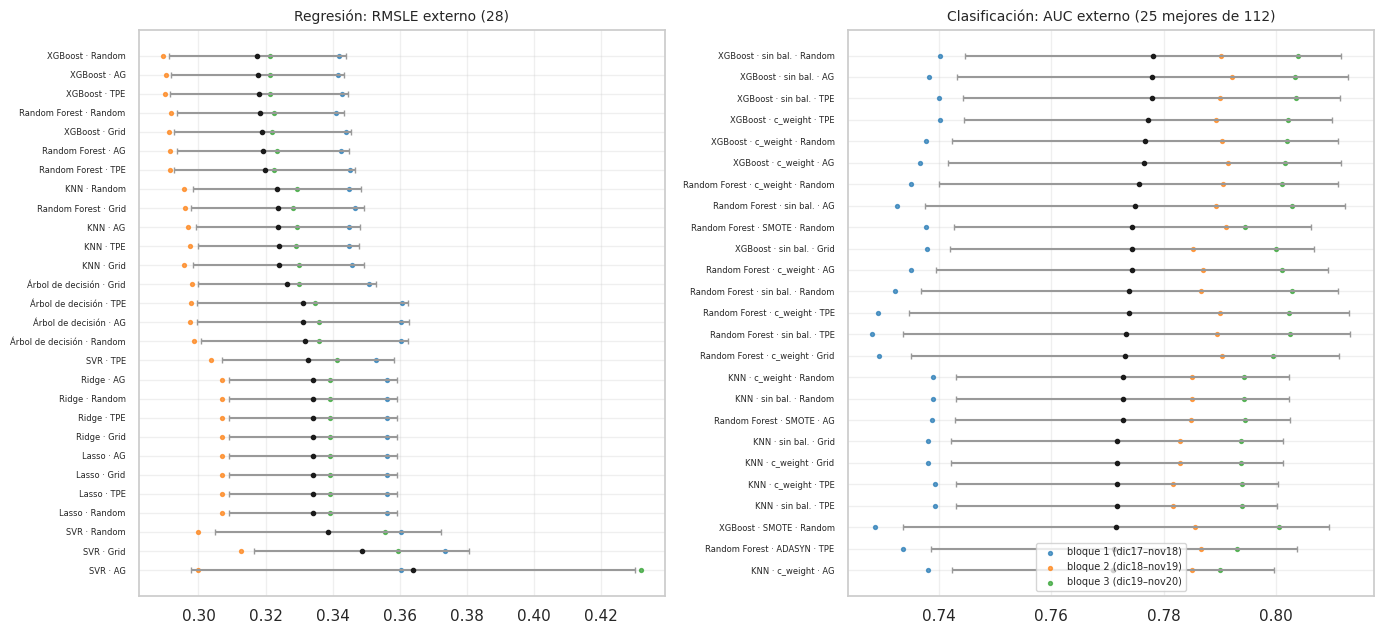

In [3]:
# Media ± desviación del bucle externo de cada combinación
fig, axs = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, (combos, met, tit, asc) in zip(axs, ((REG, "RMSLE", "Regresión: RMSLE externo (28)", True), (CLF, "ROC_AUC", f"Clasificación: AUC externo (25 mejores de {len(CLF)})", False))):
    d = pd.DataFrame([{"etiqueta": r["etiqueta"], "media": r["externo_media"], "desv": r["externo_desv"], **{f"b{k}": v for k, v in enumerate(r["externo"][met])}} for r in combos])
    d = d.sort_values("media", ascending=asc).head(28 if combos is REG else 25).iloc[::-1]
    yy = np.arange(len(d))
    ax.errorbar(d.media, yy, xerr=d.desv, fmt="o", ms=3, color="k", ecolor="0.6", capsize=2)
    for k, c in zip(range(3), ("#1f77b4", "#ff7f0e", "#2ca02c")):
        ax.scatter(d[f"b{k}"], yy, s=8, color=c, alpha=0.7, label=f"bloque {k + 1} ({['dic17–nov18', 'dic18–nov19', 'dic19–nov20'][k]})")
    ax.set_yticks(yy); ax.set_yticklabels(d.etiqueta, fontsize=6); ax.set_title(tit, fontsize=10); ax.grid(alpha=0.3)
axs[1].legend(fontsize=7)
plt.tight_layout(); eda.guardar_figura(fig, "e2_robustez_externo.png"); plt.show()

In [4]:
# Variabilidad entre bloques frente a diferencias entre modelos
def variabilidad(combos, met):
    d = pd.DataFrame([{"etiqueta": r["etiqueta"], "modelo": r["modelo"], "media": r["externo_media"], "desv": r["externo_desv"],
                       **{f"b{k}": v for k, v in enumerate(r["externo"][met])}} for r in combos])
    rango_modelos = d.media.max() - d.media.min()
    B = d[["b0", "b1", "b2"]].values
    entre_bloques = np.mean(B.max(1) - B.min(1))
    orden_bloques = pd.DataFrame(B).rank().corr(method="spearman").values[np.triu_indices(3, 1)].mean()
    return d, rango_modelos, entre_bloques, orden_bloques

dR, rmR, ebR, obR = variabilidad(REG, "RMSLE")
dC, rmC, ebC, obC = variabilidad(CLF, "ROC_AUC")
md(f"- **Regresión.** El rango de la media externa entre las 28 combinaciones es {rmR:.4f}; la diferencia típica entre el mejor y el peor "
   f"bloque de **una misma** combinación es {ebR:.4f}. El año evaluado mueve el RMSLE "
   f"{'más' if ebR > rmR else 'menos'} que el cambio de modelo. Aun así, el **orden** de las combinaciones se conserva entre bloques "
   f"(Spearman medio entre bloques = {obR:.2f}): todos los modelos suben y bajan juntos según lo difícil que sea el año.\n"
   f"- **Clasificación.** Rango entre las {len(CLF)} combinaciones: {rmC:.4f}; variación entre bloques de una combinación: {ebC:.4f}; Spearman "
   f"medio entre bloques = {obC:.2f}.\n"
   f"- Por eso las comparaciones deben ser **pareadas** (mismo bloque o mismo mes para los dos modelos): la variación común entre periodos "
   f"se cancela y queda la diferencia real entre modelos. Es lo que hacen Friedman (bloques), DeLong (mismas observaciones) y "
   f"Diebold-Mariano (mismos meses) en el cap. 21.")

- **Regresión.** El rango de la media externa entre las 28 combinaciones es 0.0466; la diferencia típica entre el mejor y el peor bloque de **una misma** combinación es 0.0552. El año evaluado mueve el RMSLE más que el cambio de modelo. Aun así, el **orden** de las combinaciones se conserva entre bloques (Spearman medio entre bloques = 0.81): todos los modelos suben y bajan juntos según lo difícil que sea el año.
- **Clasificación.** Rango entre las 112 combinaciones: 0.1003; variación entre bloques de una combinación: 0.0650; Spearman medio entre bloques = 0.59.
- Por eso las comparaciones deben ser **pareadas** (mismo bloque o mismo mes para los dos modelos): la variación común entre periodos se cancela y queda la diferencia real entre modelos. Es lo que hacen Friedman (bloques), DeLong (mismas observaciones) y Diebold-Mariano (mismos meses) en el cap. 21.

## 20.2 Sensibilidad a la semilla de inicialización

Para el campeón de cada modelo aleatorio en el origen móvil (y KNN como referencia determinista), se reentrenó
el modelo del primer origen (datos hasta 2020) con sus hiperparámetros fijos y **6 semillas** (1–5 y 42), y se
evaluó en los 12 meses de 2021 que ese origen pronostica (`scripts/semillas_origen_movil.py`). Esto aísla el
azar del propio algoritmo (bootstrap y submuestreo de columnas en RF, submuestreo en XGBoost, submuestra de
4 000 filas en la SVM); el azar del optimizador se midió en el cap. 14.6.

In [5]:
# Robustez ante la semilla: métrica de los campeones con varias semillas
S = pd.read_csv(r2.E2 / "semillas_modelos_om.csv").fillna({"balanceo": "—"})
SS = S.groupby(["tarea", "modelo", "balanceo", "optimizador", "metrica"]).valor.agg(["mean", "std", "min", "max"]).reset_index()
SS["rango"] = SS["max"] - SS["min"]
eda.guardar_tabla(SS, "e2_robustez_semillas.csv")
SS.round(5)

,tarea,modelo,balanceo,optimizador,metrica,mean,std,min,max,rango
0,clf,Random Forest,sin balanceo,Bayesiano (TPE),ROC_AUC,0.81148,0.00131,0.80950,0.81341,0.00391
1,clf,SVM,ADASYN,Bayesiano (TPE),ROC_AUC,0.79798,0.00408,0.79187,0.80262,0.01075
2,clf,XGBoost,class_weight,Bayesiano (TPE),ROC_AUC,0.81274,0.00056,0.81210,0.81338,0.00128
3,clf,Árbol de decisión,sin balanceo,Bayesiano (TPE),ROC_AUC,0.80017,0.00000,0.80017,0.80017,0.00000
4,reg,KNN,—,Bayesiano (TPE),RMSLE,0.32331,0.00000,0.32331,0.32331,0.00000
5,reg,Random Forest,—,Genético (DEAP),RMSLE,0.31507,0.00039,0.31443,0.31544,0.00101
6,reg,XGBoost,—,Bayesiano (TPE),RMSLE,0.31516,0.00019,0.31489,0.31545,0.00056
7,reg,Árbol de decisión,—,Bayesiano (TPE),RMSLE,0.31465,0.00000,0.31465,0.31465,0.00000


In [6]:
# Lectura de la robustez ante semillas
sr = SS.set_index(["tarea", "modelo"])
md(f"- **Regresión.** La desviación del RMSLE entre semillas es {sr.loc[('reg', 'XGBoost'), 'std']:.5f} en XGBoost y "
   f"{sr.loc[('reg', 'Random Forest'), 'std']:.5f} en Random Forest; KNN es determinista (desviación {sr.loc[('reg', 'KNN'), 'std']:.5f}). "
   + (lambda dif, sd: f"La diferencia entre XGBoost y Random Forest en 2021 ({dif:.4f}) es ≈ {dif / sd:.1f} veces la desviación entre semillas: "
      + ("la semilla no cambia el orden entre esos dos modelos.\n" if dif / sd > 3 else
         "no supera la variación por semilla, así que en ese año los dos modelos no se distinguen y la semilla puede invertir su orden.\n"))(
       abs(sr.loc[('reg', 'Random Forest'), 'mean'] - sr.loc[('reg', 'XGBoost'), 'mean']),
       max(sr.loc[('reg', 'XGBoost'), 'std'], sr.loc[('reg', 'Random Forest'), 'std']))
   + f"- **Clasificación.** La SVM es la más sensible (desviación del AUC {sr.loc[('clf', 'SVM'), 'std']:.4f}, rango {sr.loc[('clf', 'SVM'), 'rango']:.4f}), "
   f"porque cada semilla toma una submuestra distinta de 4 000 filas; XGBoost ({sr.loc[('clf', 'XGBoost'), 'std']:.4f}) y Random Forest "
   f"({sr.loc[('clf', 'Random Forest'), 'std']:.4f}) son muy estables. El árbol de decisión es determinista con estos datos (sin empates "
   f"en los cortes).\n"
   f"- **Conclusión.** La variabilidad por semilla es dos o más órdenes de magnitud menor que la variabilidad entre periodos (20.1). "
   f"Reportar una sola semilla es aceptable aquí, salvo para la SVM con submuestra.")

- **Regresión.** La desviación del RMSLE entre semillas es 0.00019 en XGBoost y 0.00039 en Random Forest; KNN es determinista (desviación 0.00000). La diferencia entre XGBoost y Random Forest en 2021 (0.0001) es ≈ 0.2 veces la desviación entre semillas: no supera la variación por semilla, así que en ese año los dos modelos no se distinguen y la semilla puede invertir su orden.
- **Clasificación.** La SVM es la más sensible (desviación del AUC 0.0041, rango 0.0108), porque cada semilla toma una submuestra distinta de 4 000 filas; XGBoost (0.0006) y Random Forest (0.0013) son muy estables. El árbol de decisión es determinista con estos datos (sin empates en los cortes).
- **Conclusión.** La variabilidad por semilla es dos o más órdenes de magnitud menor que la variabilidad entre periodos (20.1). Reportar una sola semilla es aceptable aquí, salvo para la SVM con submuestra.

## 20.3 Intervalos de confianza BCa en el origen móvil 2021–2026

Bootstrap de **bloques de meses** (las celdas de un mismo mes se remuestrean juntas porque no son
independientes, cap. 18.3), 1 000 réplicas, con corrección de sesgo y aceleración (BCa, Efron, 1987): la
distribución de RMSLE y AUC es asimétrica (unos pocos meses de enjambre pesan mucho) y el intervalo
percentil simple quedaría mal centrado.

In [7]:
# IC 95 % BCa del RMSLE por bootstrap de meses (regresión)
filas = []
pred_reg = {k: v for k, v in O.items() if " · " in k}
pred_reg["A+B v2 (propuesto)"] = O["A+B v2"]
for nom, p in pred_reg.items():
    b = ev.bootstrap_meses(O["y"], p, O["tm"], B=1000)
    f = b.set_index("métrica").loc["RMSLE"]
    filas.append({"modelo": nom, "RMSLE": f["valor"], "IC95 BCa inf": f["IC_BCa_inf"], "IC95 BCa sup": f["IC_BCa_sup"],
                  "IC95 perc. inf": f["IC_perc_inf"], "IC95 perc. sup": f["IC_perc_sup"]})
ICR = pd.DataFrame(filas).sort_values("RMSLE")
eda.guardar_tabla(ICR, "e2_robustez_ic_reg.csv")
ICR.round(4)

,modelo,RMSLE,IC95 BCa inf,IC95 BCa sup,IC95 perc. inf,IC95 perc. sup
28,A+B v2 (propuesto),0.3260,0.3122,0.3502,0.3094,0.3455
23,XGBoost · AG,0.3263,0.3125,0.3505,0.3097,0.3458
22,XGBoost · TPE,0.3270,0.3132,0.3513,0.3104,0.3466
21,XGBoost · Random,0.3272,0.3134,0.3515,0.3106,0.3469
18,Random Forest · TPE,0.3279,0.3141,0.3523,0.3109,0.3478
19,Random Forest · AG,0.3279,0.3140,0.3526,0.3108,0.3479
20,XGBoost · Grid,0.3285,0.3145,0.3532,0.3114,0.3484
17,Random Forest · Random,0.3291,0.3153,0.3541,0.3122,0.3490
12,Árbol de decisión · Grid,0.3297,0.3163,0.3529,0.3135,0.3486
14,Árbol de decisión · TPE,0.3308,0.3168,0.3557,0.3135,0.3510


In [8]:
# IC 95 % BCa del AUC por bootstrap de meses (clasificación)
yb = C["y"]; tmt = C["tm"]
filas = []
for etq in r2.campeones_om("clf").etiqueta:
    s = C["combos"][etq]
    b = est.bca_meses(lambda idx: roc_auc_score(yb[idx], s[idx]), tmt, B=1000)
    filas.append({"modelo": etq, "AUC": b["valor"], "IC95 BCa inf": b["IC_BCa_inf"], "IC95 BCa sup": b["IC_BCa_sup"],
                  "IC95 perc. inf": b["IC_perc_inf"], "IC95 perc. sup": b["IC_perc_sup"]})
ICC = pd.DataFrame(filas).sort_values("AUC", ascending=False)
eda.guardar_tabla(ICC, "e2_robustez_ic_clf.csv")
ICC.round(4)

,modelo,AUC,IC95 BCa inf,IC95 BCa sup,IC95 perc. inf,IC95 perc. sup
0,XGBoost · c_weight,0.8096,0.7994,0.8177,0.8001,0.8182
3,Random Forest · sin bal.,0.8074,0.7977,0.8157,0.7982,0.8159
1,Regresión logística (L1/L2) · sin bal.,0.8008,0.7910,0.8096,0.7912,0.8099
5,KNN · sin bal.,0.8005,0.7899,0.8090,0.7905,0.8094
4,Árbol de decisión · sin bal.,0.7981,0.7884,0.8072,0.7886,0.8073
2,SVM · ADASYN,0.7936,0.7828,0.8033,0.7834,0.8038
6,Naive Bayes · ADASYN,0.7889,0.7789,0.7973,0.7794,0.7976


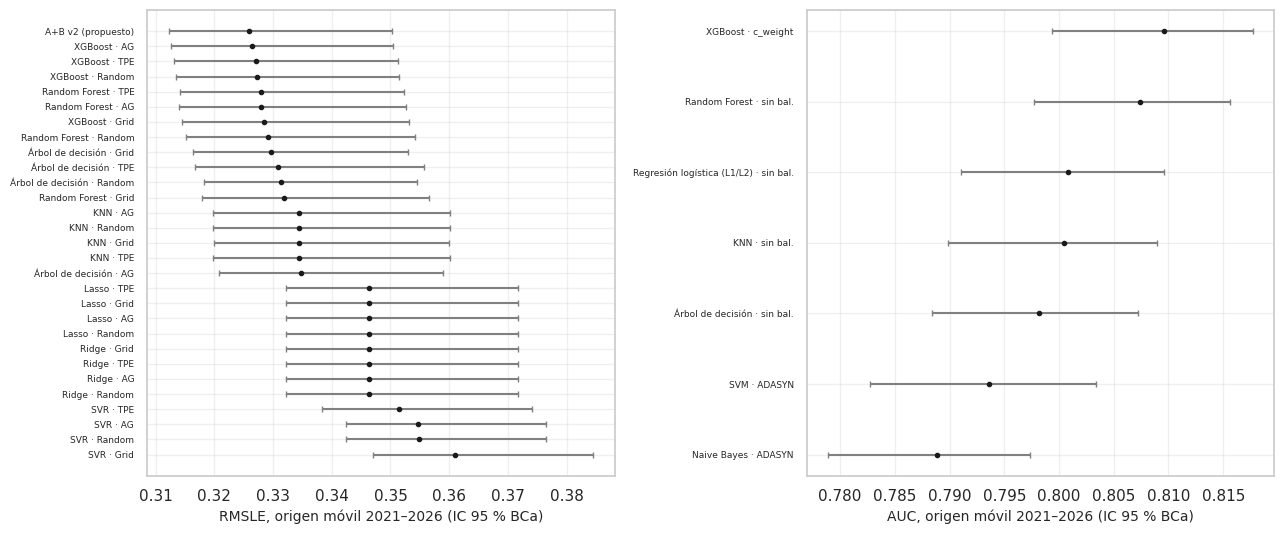

In [9]:
# Gráfico de los intervalos de confianza
fig, axs = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (d, met) in zip(axs, ((ICR.iloc[::-1], "RMSLE"), (ICC.iloc[::-1], "AUC"))):
    yy = np.arange(len(d))
    ax.errorbar(d[met], yy, xerr=[d[met] - d["IC95 BCa inf"], d["IC95 BCa sup"] - d[met]], fmt="o", ms=3, color="k", ecolor="0.5", capsize=2)
    ax.set_yticks(yy); ax.set_yticklabels(d.modelo, fontsize=6.5); ax.set_xlabel(f"{met}, origen móvil 2021–2026 (IC 95 % BCa)"); ax.grid(alpha=0.3)
plt.tight_layout(); eda.guardar_figura(fig, "e2_robustez_ic.png"); plt.show()

## 20.4 ¿Las diferencias entre modelos superan la variabilidad intrínseca?

In [10]:
# Lectura de los intervalos
ab = ICR[ICR.modelo == "A+B v2 (propuesto)"].iloc[0]
_cx = r2.campeones_om("reg"); _cx = _cx[_cx.modelo == "XGBoost"].etiqueta.iloc[0]
b2 = ICR[ICR.modelo == _cx].iloc[0]
anchoR = (ICR["IC95 BCa sup"] - ICR["IC95 BCa inf"]).median(); anchoC = (ICC["IC95 BCa sup"] - ICC["IC95 BCa inf"]).median()
md(f"- El ancho típico del IC 95 % del RMSLE en el origen móvil es {anchoR:.4f}, mientras que la distancia entre A+B v2 ({ab.RMSLE:.4f}) y el campeón "
   f"de XGBoost ({b2.modelo}, {b2.RMSLE:.4f}) es {b2.RMSLE - ab.RMSLE:.4f}: los intervalos **marginales** se solapan casi por completo. "
   f"En clasificación pasa lo mismo: ancho típico {anchoC:.4f} frente a una distancia de {ICC.AUC.iloc[0] - ICC.AUC.iloc[1]:.4f} entre los dos "
   f"primeros.\n"
   f"- Mirar si los intervalos se solapan sería **engañoso**: cada intervalo incluye la variación común a todos los modelos (meses fáciles y "
   f"difíciles para todos), que es la mayor parte de su ancho (20.1). La pregunta correcta es si la **diferencia pareada**, mes a mes, es "
   f"distinta de cero, y su variabilidad es mucho menor que la de cada métrica por separado.\n"
   f"- Frente a los modelos más débiles, las diferencias son mucho **mayores** que la variabilidad por semilla (20.2); entre los mejores "
   f"(XGBoost, Random Forest y A+B v2) son del mismo orden, así que solo una prueba pareada sobre muchos meses puede separarlos.\n"
   f"- Esto motiva directamente el cap. 21: pruebas formales **pareadas** y con control de comparaciones múltiples (Friedman–Nemenyi, "
   f"DeLong, MCS, Diebold-Mariano, SPA), en lugar de juzgar por la superposición de intervalos.")

- El ancho típico del IC 95 % del RMSLE en el origen móvil es 0.0387, mientras que la distancia entre A+B v2 (0.3260) y el campeón de XGBoost (XGBoost · TPE, 0.3270) es 0.0010: los intervalos **marginales** se solapan casi por completo. En clasificación pasa lo mismo: ancho típico 0.0185 frente a una distancia de 0.0022 entre los dos primeros.
- Mirar si los intervalos se solapan sería **engañoso**: cada intervalo incluye la variación común a todos los modelos (meses fáciles y difíciles para todos), que es la mayor parte de su ancho (20.1). La pregunta correcta es si la **diferencia pareada**, mes a mes, es distinta de cero, y su variabilidad es mucho menor que la de cada métrica por separado.
- Frente a los modelos más débiles, las diferencias son mucho **mayores** que la variabilidad por semilla (20.2); entre los mejores (XGBoost, Random Forest y A+B v2) son del mismo orden, así que solo una prueba pareada sobre muchos meses puede separarlos.
- Esto motiva directamente el cap. 21: pruebas formales **pareadas** y con control de comparaciones múltiples (Friedman–Nemenyi, DeLong, MCS, Diebold-Mariano, SPA), en lugar de juzgar por la superposición de intervalos.

## 20.5 Conclusiones del capítulo

- La métrica de un modelo depende más del **periodo evaluado** que de la semilla o del optimizador; el orden
  entre modelos, en cambio, es estable entre periodos.
- La semilla importa poco salvo en la SVM con submuestra.
- Los IC BCa de cada modelo son anchos y se solapan, pero eso no dice nada sobre la diferencia **pareada**;
  esa se prueba formalmente en el cap. 21.